In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed manifold; confirm it is an elongated (linear) cloud, not two blobs
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
adata

whole malignant manifold: 5914 cells
UMAP aspect ratio (major/minor std): 3.71


AnnData object with n_obs × n_vars = 5914 × 15317
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'hpca.celltype', 'encode.celltype', 'subtype', 'tumor_stage', 'tumor_grade', 'ct_response', 'celltype', 'lobe', 'cycling'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'lobe', 'lobe_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_lin'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [ ]:
# score the three embryonic modules (union control pool) + graph-smooth for geography
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]

Gast: 66/81 genes present
pSom: 78/98 genes present
Crest: 95/104 genes present


In [ ]:
# biology before geometry: is the manifold one axis, and is cycling a confound?
print('smoothed spatial correlations (whole manifold):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
# proliferation confound: does the pSom-Crest axis survive within NON-CYCLING cells?
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
print('proliferation confound (Spearman module vs g2m_score):')
for m in ['Gast', 'pSom', 'Crest']:
    rho, _ = spearmanr(g2m, adata.obs[m].values); print(f'  {m} vs g2m: rho = {rho:+.2f}')
nc = adata.obs['cell_cycle_phase'] == 'Not cycling'
r_all = np.corrcoef(adata.obs['pSom'], adata.obs['Crest'])[0, 1]
r_nc  = np.corrcoef(adata.obs.loc[nc, 'pSom'], adata.obs.loc[nc, 'Crest'])[0, 1]
print(f'pSom vs Crest (raw): all r={r_all:+.2f} | non-cycling only (n={int(nc.sum())}) r={r_nc:+.2f}')
print('-> pSom/Crest inverse axis holds within non-cycling cells; NOT a proliferation artifact.')
print('   developmental axis is orthogonal to the cycling pocket -> keep the whole manifold.')
sub = adata

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.61
  Crest_sm vs Gast_sm: r = -0.78
  Crest_sm vs pSom_sm: r = -0.95
proliferation confound (Spearman module vs g2m_score):
  Gast vs g2m: rho = +0.01
  pSom vs g2m: rho = +0.21
  Crest vs g2m: rho = -0.20
pSom vs Crest (raw): all r=-0.67 | non-cycling only (n=3645) r=-0.62
-> pSom/Crest inverse axis holds within non-cycling cells; NOT a proliferation artifact.
   developmental axis is orthogonal to the cycling pocket -> keep the whole manifold.


In [ ]:
# fit a principal CURVE (non-branching topology) + fold diagnostic.
# curve, not tree: PPT branch-node counts are unstable across params (3-8, no reproducible
# fork); Gast/pSom do NOT diverge into competing arms (r~0), so no bifurcation to fit.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'
print('fold-free 2-tip curve -> non-branching topology confirmed on the embedding, not a metric.')

curve: 2 tips, 0 forks | self-approach ratio = 2.97 (>1 = fold-free)
fold-free 2-tip curve -> non-branching topology confirmed on the embedding, not a metric.


In [ ]:
# root at the developmental origin: the Gast/pSom-high, Crest-low tip (Crest is LATE).
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=+0.225 pSom=+0.463 Crest=-0.423
tip 2: Gast=+0.100 pSom=+0.244 Crest=-0.163
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.806  p = 0.0e+00
  pSom_sm: rho = -0.622  p = 0.0e+00
  Crest_sm: rho = +0.783  p = 0.0e+00


milestones: {'0': 'Gast/pSom origin', '2': 'Crest terminus'}


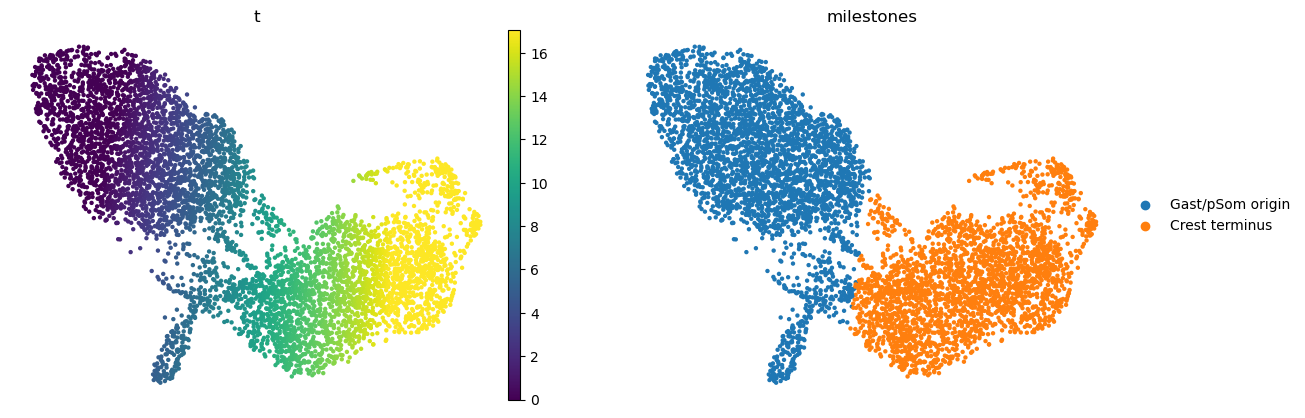

In [ ]:
# visual inspection — pseudotime + rename milestones (root/terminus)
sub.obs['milestones'] = sub.obs['milestones'].astype('category')
ms = sub.obs['milestones'].cat.categories.tolist()
tmean = {m: sub.obs.loc[sub.obs['milestones'] == m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m] == min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(sub, new=newnames)
print('milestones:', newnames)
sc.pl.umap(sub, color=['t', 'milestones'], size=40, frameon=False)

In [ ]:
# orientation consistency: reuse the house X_umap_lin from 01, verify vs pseudotime
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:, 0], sub.obs['t'].values)[0, 1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:                                    # ensure root/origin remains on the LEFT
    sub.obsm['X_umap_lin'][:, 0] = -sub.obsm['X_umap_lin'][:, 0]
    r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


In [ ]:
# sanitize non-serializable ElPiGraph uns entry, then save manifold
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (5914, 15317)


saved manifold.pdf


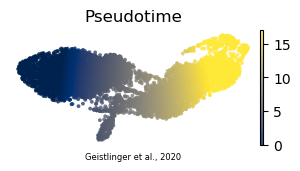

In [ ]:
# deliverable: manifold.pdf - pseudotime on the house linear layout (3.5,1.5)
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Geistlinger et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')